In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import utils

In [2]:
df = pd.read_excel("./ej4/datospractico6csdatos.xlsx", sheet_name="Arroyos Fco-Qcas")

In [3]:
df

,Cuenca,Arroyo,sitio,P-PO4,N-NO3,N-NO2,N-NH4,DBO 5,DQO,Conduct,OD
0,Langueyu,Langueyu,L1,"0,38","6,54","0,85","0,02","2,00","15,00","847,00","6,69"
1,Langueyu,Langueyu,L2,"1,21","8,06","1,14","0,34","40,00","46,00","1138,00","6,74"
2,Langueyu,Langueyu,L3,"1,27","7,34","1,14","0,31","47,00","54,00","1207,00","3,97"
3,Langueyu,Langueyu,L4,"1,29","2,67","1,21","0,33","31,00","47,00","1188,00","1,10"
4,Langueyu,Langueyu,L5,"1,29","7,34","1,17","0,45","45,00","59,00","1175,00","2,08"
5,Langueyu,Langueyu,L6,"1,12","5,29","0,68","0,55","32,00","37,00","1123,00","1,61"
6,Langueyu,San Gabriel,SG1,"0,09","0,36","0,01","0,18","0,00","1,00","244,00","10,17"
7,Langueyu,San Gabriel,SG2,"0,05","0,30","0,00","0,00","5,00","9,00","436,00","8,97"
8,Langueyu,Blanco,B1,"0,06","1,07","0,01","0,06","1,00","3,00","742,00","8,78"
9,Langueyu,Blanco,B2,"0,26","11,42","0,18","1,52","5,00","22,00","1013,00","10,99"


In [4]:
df["sitio"].value_counts()

sitio
L1     2
L2     2
L3     2
L4     2
L5     2
L6     2
SG1    2
SG2    2
B1     2
B2     2
DF1    2
DFD    2
DF2    2
Name: count, dtype: int64

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 11 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Cuenca   26 non-null     str  
 1   Arroyo   26 non-null     str  
 2   sitio    26 non-null     str  
 3   P-PO4    26 non-null     str  
 4   N-NO3    26 non-null     str  
 5   N-NO2    26 non-null     str  
 6   N-NH4    26 non-null     str  
 7   DBO 5    26 non-null     str  
 8   DQO      26 non-null     str  
 9   Conduct  26 non-null     str  
 10  OD       26 non-null     str  
dtypes: str(11)
memory usage: 2.4 KB


In [6]:
columnas = df.drop(columns=["Cuenca", "Arroyo", "sitio"]).select_dtypes(exclude="number").columns
for i in columnas:
    df[i] = df[i].str.replace(",", ".")
    df[i] = pd.to_numeric(df[i], errors="coerce")

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df = df.dropna()
df_scaled = scaler.fit_transform(df.select_dtypes(include="number"))

In [8]:
from sklearn.decomposition import PCA
pca = PCA()
principalComponents = pca.fit_transform(df_scaled)

In [9]:
for i in range(1, len(pca.explained_variance_ratio_)+1):
    print(f"PCA[{1}:{i}]: {pca.explained_variance_ratio_[:i].sum()}")

PCA[1:1]: 0.5931694573357589
PCA[1:2]: 0.8043781000137652
PCA[1:3]: 0.8769897684441422
PCA[1:4]: 0.9358253450976728
PCA[1:5]: 0.973564204642729
PCA[1:6]: 0.990317464932311
PCA[1:7]: 0.9962267822211169
PCA[1:8]: 1.0


Podemos ver que con 2 componentes tenemos un 80% de la varianza total explicada

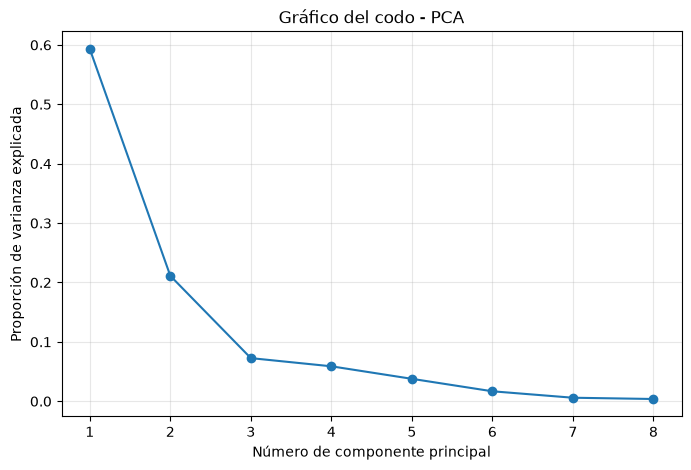

In [10]:
varianza = pca.explained_variance_ratio_

# Gráfico del codo
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(varianza) + 1),
    varianza,
    marker="o"
)

plt.xlabel("Número de componente principal")
plt.ylabel("Proporción de varianza explicada")
plt.title("Gráfico del codo - PCA")
plt.xticks(range(1, len(varianza) + 1))
plt.grid(True, alpha=0.3)
plt.show()

Vemos que nos quedariamos con 3 componentes ya que a partir de ese instante tenemos un crecimiento muy reducido por incremento de componente

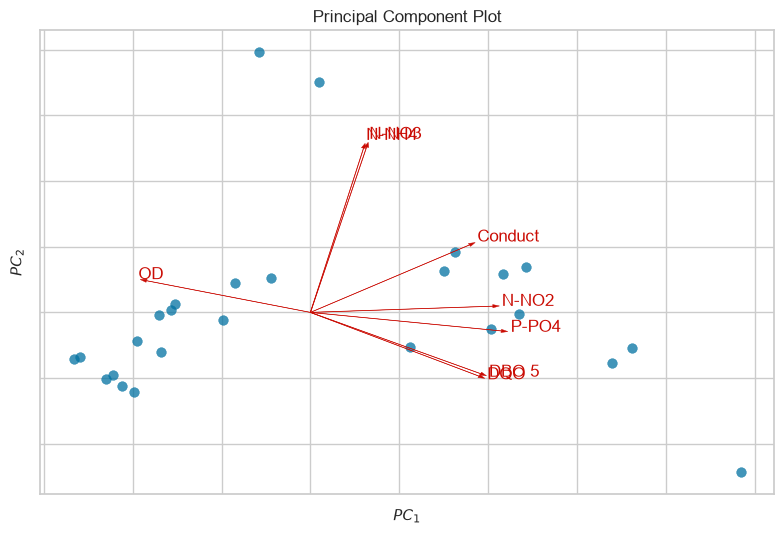

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [11]:
from yellowbrick.features import PCA as PcaViz

# declaramos un objeto de la clase PcaViz:
viz = PcaViz(
    scale=True,          # le vamos a pedir que estandarice (si le pasáramos datos estandarizados esto va en false)
    proj_features=True,  # le pedimos que dibuje las proyecciones de la features originales
    projection=2,        # le pedimos dos proyecciones
)
# lo aplicamos sobre los datos originales
df_viz = df.select_dtypes(include="number")
viz.fit_transform(df_viz)
# y pedimos que se grafique
viz.show()

Tenemos que
- DBO 5 y DQO estan altamente relacionadas entre si y por consiguiente son redundantes.

- NO3 y NH4 estan altamente relacionadas entre si y por consiguiente son redundantes.

- QD y P-PO4 son inversas entre si.

- QD es la unica variable que no aporta al crecimiento de la componente 1 y ademas, P-PO4, DBO 5 y DBO son los que aportan negativamente a la componente 2.

In [12]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(df_scaled)

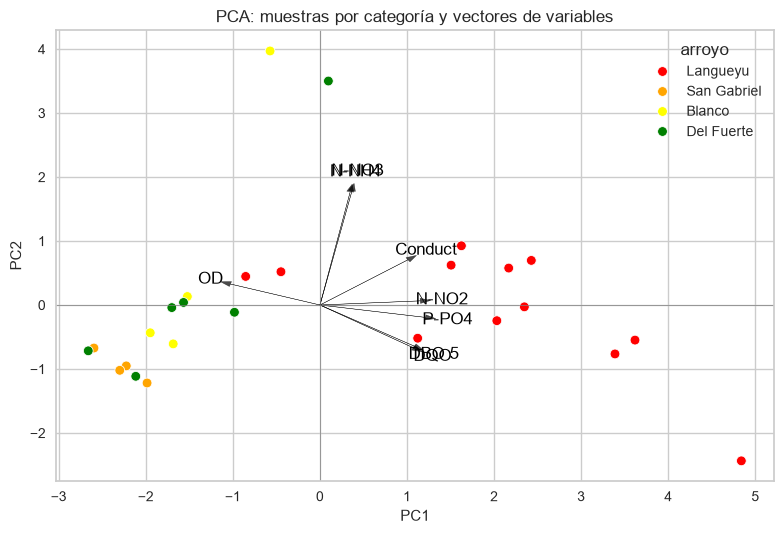

In [14]:
X = df.select_dtypes(include="number")
y = df["Arroyo"]
# DataFrame con las coordenadas de las muestras
df_pca = pd.DataFrame({
    "PC1": principalComponents[:, 0],
    "PC2": principalComponents[:, 1],
    "arroyo": y.values
})

# Graficar muestras
ax = sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="arroyo",
    palette=["red", "orange", "yellow", "green"],
)

# Agregar vectores de las variables
escala = 3  # Ajustá este valor si las flechas quedan muy chicas o grandes

for i, variable in enumerate(X.columns):
    x_vector = pca.components_[0, i] * escala
    y_vector = pca.components_[1, i] * escala

    ax.arrow(
        0, 0,
        x_vector, y_vector,
        color="black",
        alpha=0.7,
        head_width=0.08,
        length_includes_head=True
    )

    ax.text(
        x_vector * 1.1,
        y_vector * 1.1,
        variable,
        color="black",
        ha="center",
        va="center"
    )

plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)
plt.title("PCA: muestras por categoría y vectores de variables")
plt.tight_layout()
plt.show()

Podemos ver que

- El arroyo Langueyu se agrupa, a diferencia del resto, en direccion positivas de conductivimos de electricidad, nitrogeno como nitrito y fosforo como fosfato.

- Ademas, podemos ver como la gran mayoria de arroyos se encuentran en valos similares de N-NO3 y N-NH4.

- Por otro lado, podemos que los arroyos San Gabriel, Blanco y Del Fuerte comparten grupos practicamente similares.